# 19F chemical shift prediction

Predict the 19F chemical shifts of a molecule from its structure. Use the atom indices to display predictions on the molecular graph or compare them with measured peaks.

Use the solid-state NMRNet checkpoint to generate atomwise F/P predictions for the prepared molecular geometries. The benchmark scores the saved predictions against the exact paired LMDB references. Supply the frozen-inference directory and select the cross-domain comparison option.

This tutorial loads the saved predictions, explains the input/output fields and evaluates the results. Use the final command to run the model on a new dataset.

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('nmr.forward.19F')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: nmr.forward.19F
Examples: 3


## Inputs and outputs

| Field | Meaning |
| --- | --- |
| `smiles / geometry` | A valid molecular graph and a compatible 3D conformer; atom order must be preserved. |
| `nucleus` | 19F; the checkpoint must cover this nucleus. |
| `reference peaks` | Optional measured ppm values for evaluation; not an inference input. |

| Field | Meaning |
| --- | --- |
| `prediction_ppm` | Per-atom chemical shifts in ppm, with atom indices or a peak list. |
| `error / coverage` | Reference-matched errors and peak coverage. |

Inspect the example records below. Long arrays show their length and first values; the downloadable JSON contains the complete arrays.

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "input": {
    "smiles": "CCC(C)NC(=O)/C(F)=C(\\c1ccccc1)C(C)C(=O)OCC",
    "nucleus": "F",
    "atom_indices": [
      8
    ]
  },
  "output": {
    "prediction_ppm": 262.4828796386719
  },
  "reference": {
    "ppm": -121.01998138427734
  }
}
{
  "input": {
    "smiles": "CC(C)OC1(c2ccc(F)cc2)CCCCC1",
    "nucleus": "F",
    "atom_indices": [
      9
    ]
  },
  "output": {
    "prediction_ppm": 254.3622283935547
  },
  "reference": {
    "ppm": -116.1999740600586
  }
}
{
  "input": {
    "smiles": "CC(=O)C(F)S(=O)(=O)c1ccccc1",
    "nucleus": "F",
    "atom_indices": [
      4
    ]
  },
  "output": {
    "prediction_ppm": 303.3087158203125
  },
  "reference": {
    "ppm": -179.58999633789062
  }
}


## Evaluate the predictions

MAE and RMSE are reported in ppm.

The table gives the dataset and metric for each run. The following calculation recomputes summary values from the plotted predictions.

In [3]:
display(Markdown(results_table(evidence, True)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded evaluation | recorded model | mae_ppm | 356.345 |
| recorded evaluation | recorded model | rmse_ppm | 364.396 |
| recorded evaluation | recorded model | examples | 32 |


{
  "paired_values": 32,
  "mae": 356.34472984075546,
  "rmse": 364.3964037406484,
  "unit": "ppm"
}


## Visualize the result

Predicted and reference values.

Compare the prediction with the reference and inspect the returned structures or peak positions. The plot is generated directly from the records loaded above.

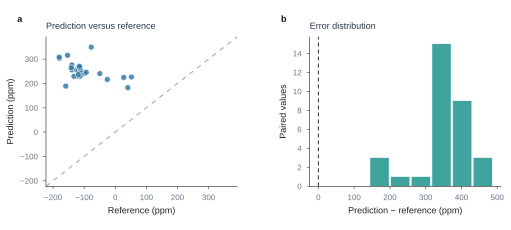

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('nmr.forward.19F', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## Run the model

Configure the runtime and weights following the task guide. Select this task in the benchmark runner to evaluate your dataset.

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks nmr.forward.19F --fp-inference-root /path/to/frozen-fp --allow-cross-domain-diagnostic --limit 8 --output results/nmr-forward-19F.json
```

[Task](../tasks/nmr-forward-19F.md) · [Quick start](../quickstart.md)



## References

- Xu, F., Guo, W., Wang, F., Yao, L., Wang, H., Tang, F., Gao, Z., Zhang, L., E, W., Tian, Z.-Q., et al. Toward a unified benchmark and framework for deep learning-based prediction of nuclear magnetic resonance chemical shifts. Nature Computational Science 5, 292–300 (2025). doi:10.1038/s43588-025-00783-z. [Source](https://doi.org/10.1038/s43588-025-00783-z)
- OpenDataLab. WanJuan MolSpectra, version 1.0.3. Experimental molecular spectroscopy dataset. [Source](https://opendatalab.com/)
